# Credit Scoring Capstone
## Notebook 02 — Base Model Development and Benchmarking

This notebook develops and evaluates the individual credit-scoring models.

### Objectives
- Load the cleaned application dataset
- Create reproducible training, validation, and test sets
- Define model-specific preprocessing pipelines
- Develop a baseline Logistic Regression model
- Develop a Weight of Evidence Logistic Regression model
- Develop an XGBoost model
- Develop a PyTorch Multi-Layer Perceptron
- Compare predictive performance across the base models
- Save trained models and preprocessing objects for later stacking

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    f1_score
)

pd.set_option("display.max_columns", None)

## 1. Load Cleaned Dataset

The cleaned dataset produced in Notebook 01 is loaded as the starting point
for model development.

In [5]:
data_path = "../data/application_clean.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (307511, 125)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_ANOM,AGE_YEARS,EMPLOYED_YEARS
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0,25.902806,1.744011
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0,45.900068,3.252567
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [7]:
exclude_features = [
    "SK_ID_CURR",
    "TARGET",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

X = df.drop(columns=exclude_features)
y = df["TARGET"]

applicant_ids = df["SK_ID_CURR"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (307511, 121)
Target shape: (307511,)


## 2. Train, Validation, and Test Split

The dataset is divided into three subsets:

- **Training set (70%)** — model development
- **Validation set (15%)** — model evaluation and later calibration
- **Test set (15%)** — final held-out evaluation

Stratified splitting is used to preserve the approximately 8% default rate
across all three subsets.

The test set will remain untouched during model development.

In [10]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.17647,
    random_state=42,
    stratify=y_temp
)

In [12]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (215257, 121)
Validation: (46127, 121)
Test: (46127, 121)


In [14]:
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Rows": [
        len(y_train),
        len(y_val),
        len(y_test)
    ],
    "Default_Rate": [
        y_train.mean(),
        y_val.mean(),
        y_test.mean()
    ]
})

split_summary

,Dataset,Rows,Default_Rate
0,Training,215257,0.080727
1,Validation,46127,0.080734
2,Test,46127,0.080734


### Split Interpretation

The stratified split successfully preserves the class distribution across
training, validation, and test datasets.

The training data will be used to fit the base models. The validation data
will support model comparison and later probability calibration, while the
test data is reserved for final evaluation.

Any resampling or imbalance treatment, such as SMOTE, must be applied only to
training data and never to the validation or test observations.

## 3. Save Dataset Split Indices

The row indices for the training, validation, and test sets are saved so that
later notebooks can reconstruct exactly the same data partitions.

This avoids accidentally creating different train/test assignments when
stacking, calibration, financial analysis, or explainability are performed.

In [18]:
split_indices = pd.DataFrame({
    "index": np.concatenate([
        X_train.index,
        X_val.index,
        X_test.index
    ]),
    "split": (
        ["train"] * len(X_train)
        + ["validation"] * len(X_val)
        + ["test"] * len(X_test)
    )
})

split_indices.head()

,index,split
0,163667,train
1,140470,train
2,91501,train
3,118815,train
4,99896,train


In [20]:
print(split_indices["split"].value_counts())
print("\nTotal rows:", len(split_indices))
print("Unique indices:", split_indices["index"].nunique())

split
train         215257
validation     46127
test           46127
Name: count, dtype: int64

Total rows: 307511
Unique indices: 307511


In [22]:
split_indices.to_csv(
    "../data/split_indices.csv",
    index=False
)

print("Split indices saved.")

Split indices saved.


## 4. Predictor Data Types

The predictor variables are separated into numerical and categorical groups.

This distinction is required because different preprocessing operations will
later be applied to each data type.

In [25]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Categorical predictors:", len(categorical_cols))
print("Numerical predictors:", len(numerical_cols))
print("Total classified predictors:",
      len(categorical_cols) + len(numerical_cols))

Categorical predictors: 16
Numerical predictors: 105
Total classified predictors: 121


C:\Users\USER\AppData\Local\Temp\ipykernel_8956\4076468050.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


In [27]:
selected_cols = set(
    categorical_cols + numerical_cols
)

missing_from_lists = [
    col for col in X_train.columns
    if col not in selected_cols
]

print("Unclassified predictors:", missing_from_lists)

Unclassified predictors: []


In [29]:
print(
    "DAYS_EMPLOYED_ANOM is numerical:",
    "DAYS_EMPLOYED_ANOM" in numerical_cols
)

print(
    "Data type:",
    X_train["DAYS_EMPLOYED_ANOM"].dtype
)

DAYS_EMPLOYED_ANOM is numerical: True
Data type: int64


### Data-Type Validation

All 121 predictor variables were successfully classified as either numerical
or categorical.

Numerical variables are identified using all numeric data types rather than
specific types such as `int64` or `float64`. This ensures that numerical
features stored using alternative numeric types, such as the engineered
`DAYS_EMPLOYED_ANOM` indicator, are not accidentally excluded from the
modelling pipeline.

## 5. Baseline Logistic Regression

A standard Logistic Regression model is used as the first benchmark.

Model-specific preprocessing is performed within a Scikit-learn pipeline:

- Numerical variables: median imputation followed by standardization
- Categorical variables: explicit missing-value category followed by one-hot encoding
- Class imbalance: no resampling or class weighting is applied at this stage

This provides a simple baseline against which later modelling approaches can
be compared.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

In [35]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [37]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [39]:
baseline_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [41]:
baseline_lr = Pipeline([
    ("preprocessor", baseline_preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

baseline_lr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [43]:
baseline_lr.fit(
    X_train,
    y_train
)

print("Baseline Logistic Regression fitted.")

Baseline Logistic Regression fitted.


In [45]:
lr_val_prob = baseline_lr.predict_proba(
    X_val
)[:, 1]

print("Number of predictions:", len(lr_val_prob))
print("Minimum probability:", lr_val_prob.min())
print("Maximum probability:", lr_val_prob.max())
print("Mean probability:", lr_val_prob.mean())

Number of predictions: 46127
Minimum probability: 2.303506814288591e-05
Maximum probability: 0.9873149766254665
Mean probability: 0.08092563382503183


In [47]:
lr_val_pred = (
    lr_val_prob >= 0.50
).astype(int)

lr_roc_auc = roc_auc_score(
    y_val,
    lr_val_prob
)

lr_pr_auc = average_precision_score(
    y_val,
    lr_val_prob
)

lr_brier = brier_score_loss(
    y_val,
    lr_val_prob
)

lr_f1 = f1_score(
    y_val,
    lr_val_pred
)

print(f"ROC-AUC: {lr_roc_auc:.4f}")
print(f"PR-AUC:  {lr_pr_auc:.4f}")
print(f"Brier:   {lr_brier:.4f}")
print(f"F1 @ 0.50: {lr_f1:.4f}")

ROC-AUC: 0.7515
PR-AUC:  0.2342
Brier:   0.0683
F1 @ 0.50: 0.0283


### Metric Interpretation

**ROC-AUC** measures the model's ability to rank defaulting applicants above
non-defaulting applicants across classification thresholds. Higher values
indicate stronger discrimination.

**PR-AUC** focuses more strongly on performance for the minority positive
class and is particularly useful because defaults represent only about 8% of
the dataset.

**Brier Score** measures the squared error of predicted probabilities. Lower
values indicate better probability accuracy.

**F1 Score** balances precision and recall after converting probabilities into
classes. Here, a threshold of 0.50 is reported only as a common reference
point and is not assumed to be the optimal credit decision threshold.

In [50]:
benchmark_results = []

benchmark_results.append({
    "Model": "Baseline Logistic Regression",
    "ROC_AUC": lr_roc_auc,
    "PR_AUC": lr_pr_auc,
    "Brier": lr_brier,
    "F1_0.50": lr_f1
})

pd.DataFrame(benchmark_results)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50
0,Baseline Logistic Regression,0.751461,0.234223,0.068283,0.028346


## 6. Weight of Evidence Logistic Regression

Weight of Evidence (WoE) transforms predictor values according to their
relationship with the binary target.

For each group or bin:

\[
WoE_i =
\ln\left(
\frac{\text{Distribution of Non-Defaults}_i}
{\text{Distribution of Defaults}_i}
\right)
\]

Under this convention:

- Positive WoE indicates relatively greater association with non-default.
- Negative WoE indicates relatively greater association with default.

Numerical variables are first divided into quantile-based bins, while
categorical variables use their existing categories.

All WoE mappings are learned only from the training data to prevent target
leakage.

In [53]:
from sklearn.base import BaseEstimator, TransformerMixin

In [55]:
class WoETransformer(BaseEstimator, TransformerMixin):

    def __init__(self, numerical_cols, categorical_cols,
                 n_bins=5, smoothing=0.5):
        self.numerical_cols = numerical_cols
        self.categorical_cols = categorical_cols
        self.n_bins = n_bins
        self.smoothing = smoothing

    def _calculate_woe(self, groups, y):

        temp = pd.DataFrame({
            "group": groups,
            "target": np.asarray(y)
        })

        table = temp.groupby(
            "group",
            observed=False
        )["target"].agg(["count", "sum"])

        table["default"] = table["sum"]
        table["non_default"] = (
            table["count"] - table["default"]
        )

        total_default = table["default"].sum()
        total_non_default = table["non_default"].sum()

        dist_default = (
            table["default"] + self.smoothing
        ) / (
            total_default +
            self.smoothing * len(table)
        )

        dist_non_default = (
            table["non_default"] + self.smoothing
        ) / (
            total_non_default +
            self.smoothing * len(table)
        )

        woe = np.log(
            dist_non_default / dist_default
        )

        iv = (
            (dist_non_default - dist_default)
            * woe
        ).sum()

        return woe.to_dict(), iv

    def fit(self, X, y):

        X = X.copy()

        self.numeric_edges_ = {}
        self.woe_maps_ = {}
        self.iv_ = {}

        # Numerical predictors
        for col in self.numerical_cols:

            series = X[col]

            try:
                _, edges = pd.qcut(
                    series,
                    q=self.n_bins,
                    retbins=True,
                    duplicates="drop"
                )

                edges = np.unique(edges)

                if len(edges) < 2:
                    continue

                edges[0] = -np.inf
                edges[-1] = np.inf

                groups = pd.cut(
                    series,
                    bins=edges,
                    include_lowest=True
                )

                groups = groups.astype(str)
                groups[series.isna()] = "Missing"

                woe_map, iv = self._calculate_woe(
                    groups,
                    y
                )

                self.numeric_edges_[col] = edges
                self.woe_maps_[col] = woe_map
                self.iv_[col] = iv

            except ValueError:
                continue

        # Categorical predictors
        for col in self.categorical_cols:

            groups = (
                X[col]
                .fillna("Missing")
                .astype(str)
            )

            woe_map, iv = self._calculate_woe(
                groups,
                y
            )

            self.woe_maps_[col] = woe_map
            self.iv_[col] = iv

        return self

    def transform(self, X):

        X = X.copy()
        transformed = {}

        for col in self.numerical_cols:

            if col not in self.numeric_edges_:
                transformed[col] = np.zeros(len(X))
                continue

            groups = pd.cut(
                X[col],
                bins=self.numeric_edges_[col],
                include_lowest=True
            )

            groups = groups.astype(str)
            groups[X[col].isna()] = "Missing"

            transformed[col] = (
                groups
                .map(self.woe_maps_[col])
                .fillna(0)
                .astype(float)
                .to_numpy()
            )

        for col in self.categorical_cols:

            groups = (
                X[col]
                .fillna("Missing")
                .astype(str)
            )

            transformed[col] = (
                groups
                .map(self.woe_maps_[col])
                .fillna(0)
                .astype(float)
                .to_numpy()
            )

        return pd.DataFrame(
            transformed,
            index=X.index
        )

In [57]:
woe_transformer = WoETransformer(
    numerical_cols=numerical_cols,
    categorical_cols=categorical_cols,
    n_bins=5,
    smoothing=0.5
)

X_train_woe = woe_transformer.fit_transform(
    X_train,
    y_train
)

X_val_woe = woe_transformer.transform(
    X_val
)

print("Original training shape:", X_train.shape)
print("WoE training shape:", X_train_woe.shape)

print("Original validation shape:", X_val.shape)
print("WoE validation shape:", X_val_woe.shape)

Original training shape: (215257, 121)
WoE training shape: (215257, 121)
Original validation shape: (46127, 121)
WoE validation shape: (46127, 121)


In [59]:
iv_summary = (
    pd.DataFrame({
        "Feature": list(woe_transformer.iv_.keys()),
        "IV": list(woe_transformer.iv_.values())
    })
    .sort_values(
        "IV",
        ascending=False
    )
    .reset_index(drop=True)
)

iv_summary.head(20)

,Feature,IV
0,EXT_SOURCE_3,0.309374
1,EXT_SOURCE_2,0.270265
2,EXT_SOURCE_1,0.140158
3,EMPLOYED_YEARS,0.105690
4,AGE_YEARS,0.082792
5,OCCUPATION_TYPE,0.080596
6,ORGANIZATION_TYPE,0.074921
7,NAME_INCOME_TYPE,0.055529
8,NAME_EDUCATION_TYPE,0.046979
9,AMT_GOODS_PRICE,0.041129


### Information Value

Information Value summarizes the univariate separation between default and
non-default observations after WoE grouping.

A larger IV indicates stronger separation for that individual predictor.
However, IV is not used here as an automatic feature-selection rule because
predictors with weak individual effects may still contribute useful
information when combined with other variables.

In [62]:
woe_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

woe_lr.fit(
    X_train_woe,
    y_train
)

print("WoE Logistic Regression fitted.")

WoE Logistic Regression fitted.


In [64]:
woe_val_prob = woe_lr.predict_proba(
    X_val_woe
)[:, 1]

woe_val_pred = (
    woe_val_prob >= 0.50
).astype(int)

In [66]:
woe_roc_auc = roc_auc_score(
    y_val,
    woe_val_prob
)

woe_pr_auc = average_precision_score(
    y_val,
    woe_val_prob
)

woe_brier = brier_score_loss(
    y_val,
    woe_val_prob
)

woe_f1 = f1_score(
    y_val,
    woe_val_pred
)

print(f"ROC-AUC: {woe_roc_auc:.4f}")
print(f"PR-AUC:  {woe_pr_auc:.4f}")
print(f"Brier:   {woe_brier:.4f}")
print(f"F1 @ 0.50: {woe_f1:.4f}")

ROC-AUC: 0.7424
PR-AUC:  0.2160
Brier:   0.0690
F1 @ 0.50: 0.0016


In [68]:
benchmark_results.append({
    "Model": "Logistic Regression + WoE",
    "ROC_AUC": woe_roc_auc,
    "PR_AUC": woe_pr_auc,
    "Brier": woe_brier,
    "F1_0.50": woe_f1
})

pd.DataFrame(benchmark_results)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50
0,Baseline Logistic Regression,0.751461,0.234223,0.068283,0.028346
1,Logistic Regression + WoE,0.742361,0.215969,0.069031,0.001609


## 7. XGBoost

XGBoost is used as a non-linear tree-based credit-scoring model.

Unlike Logistic Regression and the neural network, feature standardization is
not required for tree-based models.

The preprocessing pipeline therefore performs:

- Median imputation for numerical variables
- Explicit missing-category imputation for categorical variables
- One-hot encoding for categorical variables

No SMOTE or class weighting is applied in this initial benchmark.

In [71]:
from xgboost import XGBClassifier

In [73]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [75]:
xgb_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

In [77]:
xgb_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [79]:
xgb_preprocessor = ColumnTransformer([
    ("num", xgb_numeric_pipeline, numerical_cols),
    ("cat", xgb_categorical_pipeline, categorical_cols)
])

In [81]:
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [83]:
xgb_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", xgb_model)
])

In [85]:
xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost fitted.")

XGBoost fitted.


In [87]:
xgb_val_prob = xgb_pipeline.predict_proba(
    X_val
)[:, 1]

xgb_val_pred = (
    xgb_val_prob >= 0.50
).astype(int)

In [89]:
print("Number of predictions:", len(xgb_val_prob))
print("Minimum probability:", xgb_val_prob.min())
print("Maximum probability:", xgb_val_prob.max())
print("Mean probability:", xgb_val_prob.mean())

Number of predictions: 46127
Minimum probability: 0.0024484713
Maximum probability: 0.70594084
Mean probability: 0.080603085


In [91]:
xgb_roc_auc = roc_auc_score(
    y_val,
    xgb_val_prob
)

xgb_pr_auc = average_precision_score(
    y_val,
    xgb_val_prob
)

xgb_brier = brier_score_loss(
    y_val,
    xgb_val_prob
)

xgb_f1 = f1_score(
    y_val,
    xgb_val_pred
)

print(f"ROC-AUC: {xgb_roc_auc:.4f}")
print(f"PR-AUC:  {xgb_pr_auc:.4f}")
print(f"Brier:   {xgb_brier:.4f}")
print(f"F1 @ 0.50: {xgb_f1:.4f}")

ROC-AUC: 0.7625
PR-AUC:  0.2543
Brier:   0.0675
F1 @ 0.50: 0.0384


In [93]:
benchmark_results.append({
    "Model": "XGBoost",
    "ROC_AUC": xgb_roc_auc,
    "PR_AUC": xgb_pr_auc,
    "Brier": xgb_brier,
    "F1_0.50": xgb_f1
})

benchmark_df = pd.DataFrame(
    benchmark_results
)

benchmark_df

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50
0,Baseline Logistic Regression,0.751461,0.234223,0.068283,0.028346
1,Logistic Regression + WoE,0.742361,0.215969,0.069031,0.001609
2,XGBoost,0.762461,0.254264,0.067450,0.038442


### XGBoost Interpretation

XGBoost provides a non-linear alternative to the Logistic Regression models.
Its performance will be compared using the same validation observations and
evaluation metrics.

This allows differences in discrimination, minority-class performance, and
probability accuracy to be evaluated consistently across model families.

## 8. PyTorch Multi-Layer Perceptron

A Multi-Layer Perceptron (MLP) is developed as the neural-network benchmark.

Unlike tree-based models, neural networks are sensitive to feature scale.
Therefore:

- Numerical variables are median-imputed and standardized.
- Categorical variables are imputed and one-hot encoded.
- The processed data are converted into PyTorch tensors.
- Binary Cross-Entropy with Logits Loss is used for binary classification.
- Adam is used as the optimizer.

The model produces a raw logit, which is converted into a default probability
using the sigmoid function.

In [97]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.0+cpu
CUDA available: False


In [99]:
mlp_numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [101]:
mlp_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [103]:
mlp_preprocessor = ColumnTransformer([
    ("num", mlp_numeric_pipeline, numerical_cols),
    ("cat", mlp_categorical_pipeline, categorical_cols)
])

In [105]:
X_train_mlp = mlp_preprocessor.fit_transform(
    X_train
)

X_val_mlp = mlp_preprocessor.transform(
    X_val
)

print("Original training shape:", X_train.shape)
print("MLP training shape:", X_train_mlp.shape)

print("Original validation shape:", X_val.shape)
print("MLP validation shape:", X_val_mlp.shape)

Original training shape: (215257, 121)
MLP training shape: (215257, 251)
Original validation shape: (46127, 121)
MLP validation shape: (46127, 251)


In [107]:
X_train_tensor = torch.tensor(
    X_train_mlp,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
).reshape(-1, 1)

X_val_tensor = torch.tensor(
    X_val_mlp,
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.values,
    dtype=torch.float32
).reshape(-1, 1)

In [109]:
print("X train:", X_train_tensor.shape)
print("y train:", y_train_tensor.shape)

print("X validation:", X_val_tensor.shape)
print("y validation:", y_val_tensor.shape)

print("\nX dtype:", X_train_tensor.dtype)
print("y dtype:", y_train_tensor.dtype)

X train: torch.Size([215257, 251])
y train: torch.Size([215257, 1])
X validation: torch.Size([46127, 251])
y validation: torch.Size([46127, 1])

X dtype: torch.float32
y dtype: torch.float32


In [111]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

In [113]:
torch.manual_seed(42)

In [115]:
class CreditMLP(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [117]:
input_size = X_train_tensor.shape[1]

model = CreditMLP(
    input_size=input_size
)

print(model)

CreditMLP(
  (network): Sequential(
    (0): Linear(in_features=251, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [119]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [121]:
num_epochs = 10

training_losses = []

for epoch in range(num_epochs):

    model.train()

    total_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        logits = model(X_batch)

        loss = criterion(
            logits,
            y_batch
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item() * X_batch.size(0)
        )

    epoch_loss = (
        total_loss / len(train_dataset)
    )

    training_losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Loss: {epoch_loss:.4f}"
    )

Epoch 1/10 - Loss: 0.2670
Epoch 2/10 - Loss: 0.2509
Epoch 3/10 - Loss: 0.2497
Epoch 4/10 - Loss: 0.2485
Epoch 5/10 - Loss: 0.2474
Epoch 6/10 - Loss: 0.2459
Epoch 7/10 - Loss: 0.2440
Epoch 8/10 - Loss: 0.2425
Epoch 9/10 - Loss: 0.2409
Epoch 10/10 - Loss: 0.2388


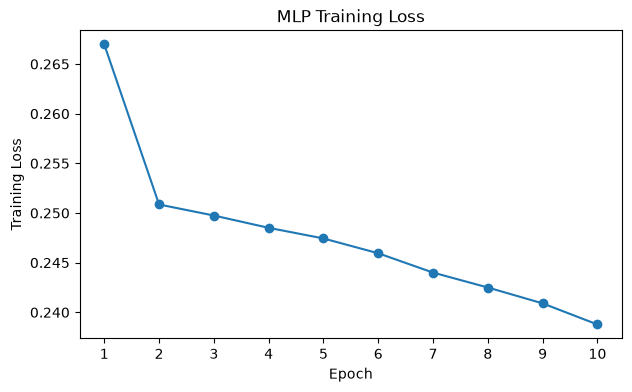

In [134]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, num_epochs + 1),
    training_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("MLP Training Loss")
plt.xticks(range(1, num_epochs + 1))

plt.show()

In [136]:
model.eval()

with torch.no_grad():

    val_logits = model(
        X_val_tensor
    )

    val_prob_mlp = (
        torch.sigmoid(val_logits)
        .cpu()
        .numpy()
        .ravel()
    )

In [138]:
print("Number of predictions:", len(val_prob_mlp))
print("Minimum probability:", val_prob_mlp.min())
print("Maximum probability:", val_prob_mlp.max())
print("Mean probability:", val_prob_mlp.mean())

Number of predictions: 46127
Minimum probability: 1.0111841e-18
Maximum probability: 0.7590571
Mean probability: 0.07878758


In [140]:
mlp_val_pred = (
    val_prob_mlp >= 0.50
).astype(int)

mlp_roc_auc = roc_auc_score(
    y_val,
    val_prob_mlp
)

mlp_pr_auc = average_precision_score(
    y_val,
    val_prob_mlp
)

mlp_brier = brier_score_loss(
    y_val,
    val_prob_mlp
)

mlp_f1 = f1_score(
    y_val,
    mlp_val_pred
)

print(f"ROC-AUC: {mlp_roc_auc:.4f}")
print(f"PR-AUC:  {mlp_pr_auc:.4f}")
print(f"Brier:   {mlp_brier:.4f}")
print(f"F1 @ 0.50: {mlp_f1:.4f}")

ROC-AUC: 0.7416
PR-AUC:  0.2147
Brier:   0.0692
F1 @ 0.50: 0.0215


In [142]:
benchmark_results.append({
    "Model": "PyTorch MLP",
    "ROC_AUC": mlp_roc_auc,
    "PR_AUC": mlp_pr_auc,
    "Brier": mlp_brier,
    "F1_0.50": mlp_f1
})

benchmark_df = pd.DataFrame(
    benchmark_results
)

benchmark_df

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50
0,Baseline Logistic Regression,0.751461,0.234223,0.068283,0.028346
1,Logistic Regression + WoE,0.742361,0.215969,0.069031,0.001609
2,XGBoost,0.762461,0.254264,0.067450,0.038442
3,PyTorch MLP,0.741574,0.214680,0.069174,0.021517


## 9. Base Model Benchmark Comparison

The four base modelling approaches are compared using the same validation
dataset and evaluation metrics.

The comparison considers:

- ROC-AUC for overall discrimination
- PR-AUC for minority-class discrimination
- Brier Score for probability accuracy
- F1 Score at a 0.50 classification threshold

Because the project ultimately uses predicted default probabilities for
calibration and financial analysis, ROC-AUC, PR-AUC, and Brier Score are
particularly important. F1 at 0.50 is included as a classification reference
but is not treated as an optimized decision threshold.

In [145]:
benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df = benchmark_df[
    [
        "Model",
        "ROC_AUC",
        "PR_AUC",
        "Brier",
        "F1_0.50"
    ]
]

benchmark_df.round(4)

,Model,ROC_AUC,PR_AUC,Brier,F1_0.50
0,Baseline Logistic Regression,0.7515,0.2342,0.0683,0.0283
1,Logistic Regression + WoE,0.7424,0.2160,0.0690,0.0016
2,XGBoost,0.7625,0.2543,0.0675,0.0384
3,PyTorch MLP,0.7416,0.2147,0.0692,0.0215


In [149]:
default_rate = y_val.mean()

print(f"Validation default rate: {default_rate:.4f}")
print(f"Random ROC-AUC reference: 0.5000")
print(f"PR-AUC prevalence reference: {default_rate:.4f}")

Validation default rate: 0.0807
Random ROC-AUC reference: 0.5000
PR-AUC prevalence reference: 0.0807


### Evaluation Context

The validation default prevalence is approximately 8%. Therefore, the
precision-recall baseline is also approximately 0.08, while the random
ROC-AUC reference is 0.50.

The Brier Score should be interpreted in the context of probability
prediction: lower values indicate smaller squared differences between
predicted default probabilities and observed outcomes.

The metrics capture different aspects of performance, so model comparison
should not rely on a single measure alone.

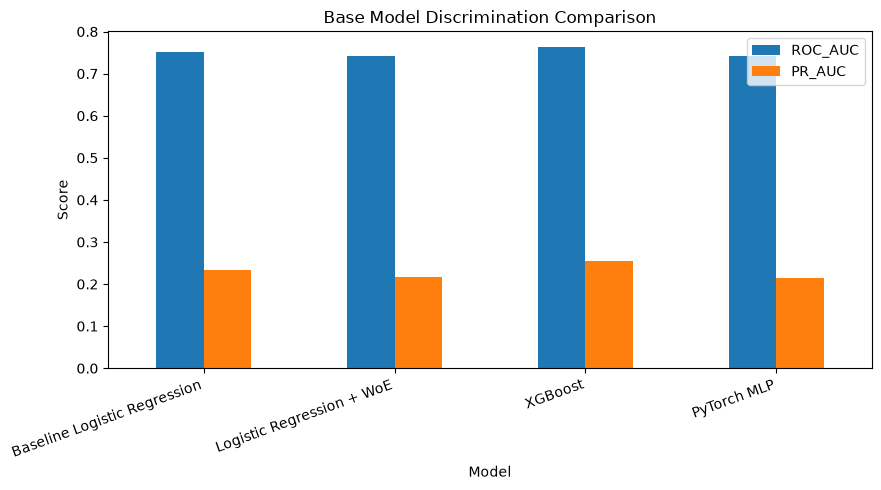

In [152]:
plot_df = benchmark_df.set_index("Model")

plot_df[
    ["ROC_AUC", "PR_AUC"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Score")
plt.title("Base Model Discrimination Comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

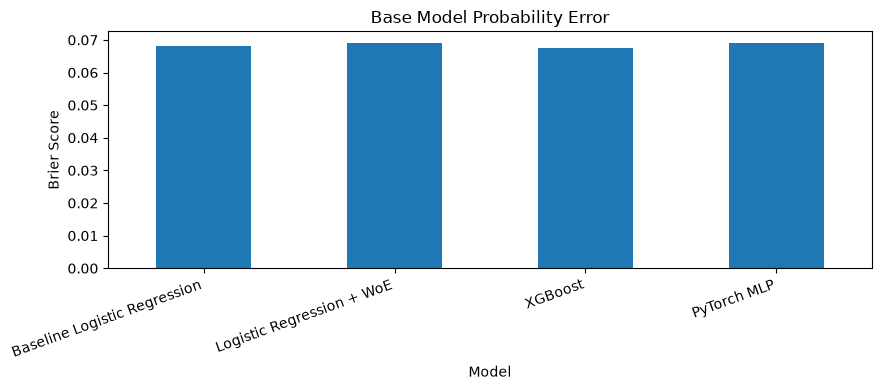

In [154]:
plot_df["Brier"].plot(
    kind="bar",
    figsize=(9, 4)
)

plt.ylabel("Brier Score")
plt.title("Base Model Probability Error")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [156]:
best_roc_model = benchmark_df.loc[
    benchmark_df["ROC_AUC"].idxmax(),
    "Model"
]

best_pr_model = benchmark_df.loc[
    benchmark_df["PR_AUC"].idxmax(),
    "Model"
]

lowest_brier_model = benchmark_df.loc[
    benchmark_df["Brier"].idxmin(),
    "Model"
]

best_f1_model = benchmark_df.loc[
    benchmark_df["F1_0.50"].idxmax(),
    "Model"
]

print("Highest ROC-AUC:", best_roc_model)
print("Highest PR-AUC:", best_pr_model)
print("Lowest Brier Score:", lowest_brier_model)
print("Highest F1 @ 0.50:", best_f1_model)

Highest ROC-AUC: XGBoost
Highest PR-AUC: XGBoost
Lowest Brier Score: XGBoost
Highest F1 @ 0.50: XGBoost


### Benchmark Interpretation

The benchmark allows the models to be compared across discrimination,
minority-class performance, probability accuracy, and threshold-based
classification.

Differences between the metrics are expected. A model with stronger ranking
ability does not necessarily produce better-calibrated probabilities, and a
model with a higher F1 score at a fixed threshold does not necessarily provide
better probability estimates.

This distinction is particularly important in this project because the
predicted probabilities will later be calibrated and used as estimates of
Probability of Default (PD).

## 10. Class-Imbalance Experiments

The dataset contains substantially fewer default observations than
non-default observations. However, resampling is not automatically assumed
to improve credit-risk modelling.

Three general strategies are considered:

1. No imbalance treatment — the existing base-model benchmark.
2. Class weighting — increase the training importance of default observations.
3. SMOTE — synthetically oversample the minority class within training data.

These methods will be compared empirically rather than assuming that
oversampling necessarily improves performance.

Any resampling method must be applied only to training observations and never
to validation or test data.

### 10.1 Class Weighting

Class weighting addresses imbalance by assigning greater importance to
minority-class observations during model training without creating synthetic
observations.

The weighted models are trained using the original training data and evaluated
on the same unchanged validation set used for the baseline models.

This experiment is performed for Logistic Regression and XGBoost to examine
whether weighting the default class improves performance.

In [162]:
weighted_lr = Pipeline([
    ("preprocessor", baseline_preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

In [164]:
weighted_lr.fit(
    X_train,
    y_train
)

print("Weighted Logistic Regression fitted.")

Weighted Logistic Regression fitted.


In [166]:
weighted_lr_val_prob = weighted_lr.predict_proba(
    X_val
)[:, 1]

weighted_lr_val_pred = (
    weighted_lr_val_prob >= 0.50
).astype(int)

In [168]:
weighted_lr_roc = roc_auc_score(
    y_val,
    weighted_lr_val_prob
)

weighted_lr_pr = average_precision_score(
    y_val,
    weighted_lr_val_prob
)

weighted_lr_brier = brier_score_loss(
    y_val,
    weighted_lr_val_prob
)

weighted_lr_f1 = f1_score(
    y_val,
    weighted_lr_val_pred
)

print(f"ROC-AUC: {weighted_lr_roc:.4f}")
print(f"PR-AUC:  {weighted_lr_pr:.4f}")
print(f"Brier:   {weighted_lr_brier:.4f}")
print(f"F1 @ 0.50: {weighted_lr_f1:.4f}")
print(f"Mean predicted PD: {weighted_lr_val_prob.mean():.4f}")

ROC-AUC: 0.7512
PR-AUC:  0.2315
Brier:   0.2035
F1 @ 0.50: 0.2615
Mean predicted PD: 0.4229


In [170]:
n_non_default = (y_train == 0).sum()
n_default = (y_train == 1).sum()

scale_pos_weight = (
    n_non_default / n_default
)

print("Non-default:", n_non_default)
print("Default:", n_default)
print(
    "scale_pos_weight:",
    round(scale_pos_weight, 4)
)

Non-default: 197880
Default: 17377
scale_pos_weight: 11.3875


In [172]:
weighted_xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1
)

In [174]:
weighted_xgb = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", weighted_xgb_model)
])

In [176]:
weighted_xgb.fit(
    X_train,
    y_train
)

print("Weighted XGBoost fitted.")

Weighted XGBoost fitted.


In [178]:
weighted_xgb_val_prob = weighted_xgb.predict_proba(
    X_val
)[:, 1]

weighted_xgb_val_pred = (
    weighted_xgb_val_prob >= 0.50
).astype(int)

In [180]:
weighted_xgb_roc = roc_auc_score(
    y_val,
    weighted_xgb_val_prob
)

weighted_xgb_pr = average_precision_score(
    y_val,
    weighted_xgb_val_prob
)

weighted_xgb_brier = brier_score_loss(
    y_val,
    weighted_xgb_val_prob
)

weighted_xgb_f1 = f1_score(
    y_val,
    weighted_xgb_val_pred
)

print(f"ROC-AUC: {weighted_xgb_roc:.4f}")
print(f"PR-AUC:  {weighted_xgb_pr:.4f}")
print(f"Brier:   {weighted_xgb_brier:.4f}")
print(f"F1 @ 0.50: {weighted_xgb_f1:.4f}")
print(f"Mean predicted PD: {weighted_xgb_val_prob.mean():.4f}")

ROC-AUC: 0.7625
PR-AUC:  0.2539
Brier:   0.1904
F1 @ 0.50: 0.2743
Mean predicted PD: 0.4035


In [182]:
weighting_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Treatment": "None",
        "ROC_AUC": lr_roc_auc,
        "PR_AUC": lr_pr_auc,
        "Brier": lr_brier,
        "F1_0.50": lr_f1,
        "Mean_PD": lr_val_prob.mean()
    },
    {
        "Model": "Logistic Regression",
        "Treatment": "Class Weighting",
        "ROC_AUC": weighted_lr_roc,
        "PR_AUC": weighted_lr_pr,
        "Brier": weighted_lr_brier,
        "F1_0.50": weighted_lr_f1,
        "Mean_PD": weighted_lr_val_prob.mean()
    },
    {
        "Model": "XGBoost",
        "Treatment": "None",
        "ROC_AUC": xgb_roc_auc,
        "PR_AUC": xgb_pr_auc,
        "Brier": xgb_brier,
        "F1_0.50": xgb_f1,
        "Mean_PD": xgb_val_prob.mean()
    },
    {
        "Model": "XGBoost",
        "Treatment": "Class Weighting",
        "ROC_AUC": weighted_xgb_roc,
        "PR_AUC": weighted_xgb_pr,
        "Brier": weighted_xgb_brier,
        "F1_0.50": weighted_xgb_f1,
        "Mean_PD": weighted_xgb_val_prob.mean()
    }
])

weighting_results.round(4)

,Model,Treatment,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,None,0.7515,0.2342,0.0683,0.0283,0.0809
1,Logistic Regression,Class Weighting,0.7512,0.2315,0.2035,0.2615,0.4229
2,XGBoost,None,0.7625,0.2543,0.0675,0.0384,0.0806
3,XGBoost,Class Weighting,0.7625,0.2539,0.1904,0.2743,0.4035


### Class-Weighting Interpretation

Class weighting changes the importance assigned to default observations during
training. Therefore, improvements in threshold-based classification metrics
such as F1 should be considered alongside discrimination metrics and
probability-based metrics.

In particular, changes in the mean predicted probability and Brier Score are
important because the final project uses model probabilities as estimates of
Probability of Default.

The weighted models are therefore not selected solely because they may identify
more default observations at a 0.50 threshold.

### 10.2 SMOTE

Synthetic Minority Over-sampling Technique (SMOTE) addresses class imbalance
by generating synthetic observations for the minority class.

To prevent data leakage, SMOTE is applied only to the training data. The
validation and test sets retain their original class distributions.

For this experiment, model preprocessing is first learned from the training
data. SMOTE is then applied to the transformed training features, and the
resulting models are evaluated on the unchanged validation set.

SMOTE is evaluated as an alternative imbalance treatment rather than assumed
to improve model performance.

In [188]:
%pip install imbalanced-learn


   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]

Note: you may need to restart the kernel to use updated packages.


In [190]:
from imblearn.over_sampling import SMOTE

print("imbalanced-learn imported successfully.")

imbalanced-learn imported successfully.


In [192]:
X_train_lr_processed = baseline_preprocessor.fit_transform(
    X_train
)

X_val_lr_processed = baseline_preprocessor.transform(
    X_val
)

print("Training shape before SMOTE:",
      X_train_lr_processed.shape)

print("Validation shape:",
      X_val_lr_processed.shape)

Training shape before SMOTE: (215257, 251)
Validation shape: (46127, 251)


In [194]:
print("Before SMOTE:")
print(y_train.value_counts())

print("\nBefore SMOTE proportions:")
print(y_train.value_counts(normalize=True))

Before SMOTE:
TARGET
0    197880
1     17377
Name: count, dtype: int64

Before SMOTE proportions:
TARGET
0    0.919273
1    0.080727
Name: proportion, dtype: float64


In [196]:
smote = SMOTE(
    random_state=42
)

X_train_lr_smote, y_train_lr_smote = (
    smote.fit_resample(
        X_train_lr_processed,
        y_train
    )
)

In [198]:
print("Training shape before SMOTE:",
      X_train_lr_processed.shape)

print("Training shape after SMOTE:",
      X_train_lr_smote.shape)

print("\nClass distribution after SMOTE:")
print(
    pd.Series(y_train_lr_smote)
    .value_counts()
)

Training shape before SMOTE: (215257, 251)
Training shape after SMOTE: (395760, 251)

Class distribution after SMOTE:
TARGET
0    197880
1    197880
Name: count, dtype: int64


In [200]:
smote_lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_lr_model.fit(
    X_train_lr_smote,
    y_train_lr_smote
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [202]:
smote_lr_val_prob = (
    smote_lr_model.predict_proba(
        X_val_lr_processed
    )[:, 1]
)

smote_lr_val_pred = (
    smote_lr_val_prob >= 0.50
).astype(int)

In [204]:
smote_lr_roc = roc_auc_score(
    y_val,
    smote_lr_val_prob
)

smote_lr_pr = average_precision_score(
    y_val,
    smote_lr_val_prob
)

smote_lr_brier = brier_score_loss(
    y_val,
    smote_lr_val_prob
)

smote_lr_f1 = f1_score(
    y_val,
    smote_lr_val_pred
)

print(f"ROC-AUC: {smote_lr_roc:.4f}")
print(f"PR-AUC:  {smote_lr_pr:.4f}")
print(f"Brier:   {smote_lr_brier:.4f}")
print(f"F1 @ 0.50: {smote_lr_f1:.4f}")
print(
    f"Mean predicted PD: "
    f"{smote_lr_val_prob.mean():.4f}"
)

ROC-AUC: 0.7430
PR-AUC:  0.2293
Brier:   0.1998
F1 @ 0.50: 0.2597
Mean predicted PD: 0.4058


In [206]:
X_train_xgb_processed = (
    xgb_preprocessor.fit_transform(
        X_train
    )
)

X_val_xgb_processed = (
    xgb_preprocessor.transform(
        X_val
    )
)

print(
    "XGBoost training shape:",
    X_train_xgb_processed.shape
)

print(
    "XGBoost validation shape:",
    X_val_xgb_processed.shape
)

XGBoost training shape: (215257, 251)
XGBoost validation shape: (46127, 251)


In [208]:
xgb_smote = SMOTE(
    random_state=42
)

X_train_xgb_smote, y_train_xgb_smote = (
    xgb_smote.fit_resample(
        X_train_xgb_processed,
        y_train
    )
)

print(
    "Before SMOTE:",
    X_train_xgb_processed.shape
)

print(
    "After SMOTE:",
    X_train_xgb_smote.shape
)

print("\nClass distribution:")
print(
    pd.Series(y_train_xgb_smote)
    .value_counts()
)

Before SMOTE: (215257, 251)
After SMOTE: (395760, 251)

Class distribution:
TARGET
0    197880
1    197880
Name: count, dtype: int64


In [210]:
smote_xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

smote_xgb_model.fit(
    X_train_xgb_smote,
    y_train_xgb_smote
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [212]:
smote_xgb_val_prob = (
    smote_xgb_model.predict_proba(
        X_val_xgb_processed
    )[:, 1]
)

smote_xgb_val_pred = (
    smote_xgb_val_prob >= 0.50
).astype(int)

In [214]:
smote_xgb_roc = roc_auc_score(
    y_val,
    smote_xgb_val_prob
)

smote_xgb_pr = average_precision_score(
    y_val,
    smote_xgb_val_prob
)

smote_xgb_brier = brier_score_loss(
    y_val,
    smote_xgb_val_prob
)

smote_xgb_f1 = f1_score(
    y_val,
    smote_xgb_val_pred
)

print(f"ROC-AUC: {smote_xgb_roc:.4f}")
print(f"PR-AUC:  {smote_xgb_pr:.4f}")
print(f"Brier:   {smote_xgb_brier:.4f}")
print(f"F1 @ 0.50: {smote_xgb_f1:.4f}")
print(
    f"Mean predicted PD: "
    f"{smote_xgb_val_prob.mean():.4f}"
)

ROC-AUC: 0.7613
PR-AUC:  0.2519
Brier:   0.0675
F1 @ 0.50: 0.0385
Mean predicted PD: 0.0830


In [216]:
imbalance_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Treatment": "None",
        "ROC_AUC": lr_roc_auc,
        "PR_AUC": lr_pr_auc,
        "Brier": lr_brier,
        "F1_0.50": lr_f1,
        "Mean_PD": lr_val_prob.mean()
    },
    {
        "Model": "Logistic Regression",
        "Treatment": "Class Weighting",
        "ROC_AUC": weighted_lr_roc,
        "PR_AUC": weighted_lr_pr,
        "Brier": weighted_lr_brier,
        "F1_0.50": weighted_lr_f1,
        "Mean_PD": weighted_lr_val_prob.mean()
    },
    {
        "Model": "Logistic Regression",
        "Treatment": "SMOTE",
        "ROC_AUC": smote_lr_roc,
        "PR_AUC": smote_lr_pr,
        "Brier": smote_lr_brier,
        "F1_0.50": smote_lr_f1,
        "Mean_PD": smote_lr_val_prob.mean()
    },

    {
        "Model": "XGBoost",
        "Treatment": "None",
        "ROC_AUC": xgb_roc_auc,
        "PR_AUC": xgb_pr_auc,
        "Brier": xgb_brier,
        "F1_0.50": xgb_f1,
        "Mean_PD": xgb_val_prob.mean()
    },
    {
        "Model": "XGBoost",
        "Treatment": "Class Weighting",
        "ROC_AUC": weighted_xgb_roc,
        "PR_AUC": weighted_xgb_pr,
        "Brier": weighted_xgb_brier,
        "F1_0.50": weighted_xgb_f1,
        "Mean_PD": weighted_xgb_val_prob.mean()
    },
    {
        "Model": "XGBoost",
        "Treatment": "SMOTE",
        "ROC_AUC": smote_xgb_roc,
        "PR_AUC": smote_xgb_pr,
        "Brier": smote_xgb_brier,
        "F1_0.50": smote_xgb_f1,
        "Mean_PD": smote_xgb_val_prob.mean()
    }
])

imbalance_results.round(4)

,Model,Treatment,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,None,0.7515,0.2342,0.0683,0.0283,0.0809
1,Logistic Regression,Class Weighting,0.7512,0.2315,0.2035,0.2615,0.4229
2,Logistic Regression,SMOTE,0.7430,0.2293,0.1998,0.2597,0.4058
3,XGBoost,None,0.7625,0.2543,0.0675,0.0384,0.0806
4,XGBoost,Class Weighting,0.7625,0.2539,0.1904,0.2743,0.4035
5,XGBoost,SMOTE,0.7613,0.2519,0.0675,0.0385,0.0830


In [218]:
print(
    "Actual validation default rate:",
    round(y_val.mean(), 4)
)

imbalance_results.round(4)

Actual validation default rate: 0.0807


,Model,Treatment,ROC_AUC,PR_AUC,Brier,F1_0.50,Mean_PD
0,Logistic Regression,None,0.7515,0.2342,0.0683,0.0283,0.0809
1,Logistic Regression,Class Weighting,0.7512,0.2315,0.2035,0.2615,0.4229
2,Logistic Regression,SMOTE,0.7430,0.2293,0.1998,0.2597,0.4058
3,XGBoost,None,0.7625,0.2543,0.0675,0.0384,0.0806
4,XGBoost,Class Weighting,0.7625,0.2539,0.1904,0.2743,0.4035
5,XGBoost,SMOTE,0.7613,0.2519,0.0675,0.0385,0.0830


### Imbalance Experiment Interpretation

The imbalance treatments are evaluated across both classification and
probability-based metrics.

An increase in F1 score does not necessarily imply better Probability of
Default estimation. Class weighting and SMOTE modify the training objective
or class distribution and may therefore change the scale of predicted
probabilities.

For this project, this trade-off is particularly important because model
probabilities are subsequently calibrated and used in Expected Loss
calculations. The imbalance strategy carried forward should therefore be
chosen based on the combined evidence from discrimination, probability
accuracy, and the later calibration stage rather than F1 alone.

## 11. Final Base-Model Configuration

The imbalance experiments showed that class weighting substantially increased
the mean predicted default probability for both Logistic Regression and
XGBoost, while providing little improvement in ROC-AUC or PR-AUC and
substantially worsening the Brier Score.

SMOTE produced more stable probability estimates for XGBoost, but did not
improve its discrimination metrics relative to the untreated model.

Because the project ultimately uses predicted probabilities as Probability of
Default estimates for calibration and financial analysis, the untreated base
models are retained for the stacking stage.

The stacking framework therefore uses:

1. Baseline Logistic Regression
2. XGBoost
3. PyTorch MLP

The WoE Logistic Regression remains as a separate interpretable benchmark.

In [222]:
from pathlib import Path

Path("../outputs").mkdir(
    parents=True,
    exist_ok=True
)

In [224]:
benchmark_df.to_csv(
    "../outputs/base_model_benchmark.csv",
    index=False
)

imbalance_results.to_csv(
    "../outputs/imbalance_experiments.csv",
    index=False
)

print("Result tables saved.")

Result tables saved.


In [226]:
import joblib

Path("../models").mkdir(
    parents=True,
    exist_ok=True
)

In [228]:
joblib.dump(
    baseline_lr,
    "../models/baseline_lr.joblib"
)

['../models/baseline_lr.joblib']

In [230]:
joblib.dump(
    xgb_pipeline,
    "../models/xgb_pipeline.joblib"
)

['../models/xgb_pipeline.joblib']

In [232]:
torch.save(
    model.state_dict(),
    "../models/mlp_state_dict.pt"
)

In [234]:
joblib.dump(
    mlp_preprocessor,
    "../models/mlp_preprocessor.joblib"
)

['../models/mlp_preprocessor.joblib']

In [236]:
mlp_metadata = {
    "input_size": input_size,
    "hidden_layer_1": 128,
    "hidden_layer_2": 64,
    "output_size": 1
}

joblib.dump(
    mlp_metadata,
    "../models/mlp_metadata.joblib"
)

['../models/mlp_metadata.joblib']

In [238]:
validation_predictions = pd.DataFrame({
    "index": X_val.index,
    "y_true": y_val.values,
    "lr_probability": lr_val_prob,
    "xgb_probability": xgb_val_prob,
    "mlp_probability": val_prob_mlp
})

validation_predictions.to_csv(
    "../outputs/base_validation_predictions.csv",
    index=False
)

validation_predictions.head()

,index,y_true,lr_probability,xgb_probability,mlp_probability
0,266395,0,0.147797,0.156580,0.186267
1,190842,0,0.029587,0.026750,0.025477
2,152795,0,0.049784,0.042667,0.100005
3,45638,0,0.177394,0.118846,0.237831
4,272293,0,0.029363,0.043425,0.032698


In [240]:
print(
    "Validation predictions:",
    validation_predictions.shape
)

print(
    validation_predictions[
        [
            "lr_probability",
            "xgb_probability",
            "mlp_probability"
        ]
    ].mean()
)

Validation predictions: (46127, 5)
lr_probability     0.080926
xgb_probability    0.080603
mlp_probability    0.078788
dtype: float64


In [242]:
files_to_check = [
    "../models/baseline_lr.joblib",
    "../models/xgb_pipeline.joblib",
    "../models/mlp_state_dict.pt",
    "../models/mlp_preprocessor.joblib",
    "../models/mlp_metadata.joblib",
    "../outputs/base_model_benchmark.csv",
    "../outputs/imbalance_experiments.csv",
    "../outputs/base_validation_predictions.csv"
]

for file in files_to_check:
    path = Path(file)

    print(
        path.name,
        "->",
        "Saved" if path.exists() else "MISSING"
    )

baseline_lr.joblib -> Saved
xgb_pipeline.joblib -> Saved
mlp_state_dict.pt -> Saved
mlp_preprocessor.joblib -> Saved
mlp_metadata.joblib -> Saved
base_model_benchmark.csv -> Saved
imbalance_experiments.csv -> Saved
base_validation_predictions.csv -> Saved


## 12. Notebook Summary

This notebook developed and compared four base credit-scoring approaches:

- Baseline Logistic Regression
- Weight of Evidence Logistic Regression
- XGBoost
- PyTorch Multi-Layer Perceptron

Additional experiments examined class weighting and SMOTE as methods for
handling the imbalanced default outcome.

The imbalance experiments demonstrated that improved classification at a fixed
threshold does not necessarily correspond to improved probability estimation.
Class weighting substantially altered the predicted probability scale and
increased Brier error, while SMOTE did not provide a clear improvement over
the untreated XGBoost model.

The untreated Baseline Logistic Regression, XGBoost, and PyTorch MLP are
therefore retained as the three base learners for the stacking framework.

The next stage generates out-of-fold predictions from these base learners,
trains a Meta-Logistic Regression model, and evaluates probability calibration
using Platt scaling and Isotonic Regression.